# Company Bankruptcy Prediction
## Notebook 3: Model Training, Evaluation and Selection

### Objective

To develop and evaluate machine learning classification models that predict corporate bankruptcy from financial indicators. The dataset is highly imbalanced (only 3.23% of companies are bankrupt), so special attention is given to class imbalance handling and to the performance on the minority (bankrupt) class.

### Workflow

1. Setup and load dataset
2. Separate features and target
3. Stratified train-test split
4. Verify class distribution after splitting
5. Class imbalance handling strategy
6. Feature scaling and preprocessing
7. Build preprocessing and resampling pipelines
8. Model evaluation using cross-validation
9. Candidate model selection
10. Voting classifier (ensemble learning)
11. Hyperparameter tuning
12. Final model evaluation on the test set
13. ROC and Precision-Recall curves
14. Feature importance
15. Classification threshold optimization
16. Final model performance comparison
17. Final conclusion

# Bankruptcy Prediction Using Machine Learning

## 1. Setup and Load Dataset

The objective of this notebook is to develop and evaluate machine learning classification models to predict corporate bankruptcy.

The dataset is highly imbalanced, with only 3.23% of companies belonging to the bankrupt class. Therefore, special attention will be given to class imbalance handling and the evaluation of minority-class prediction performance.

In this section, we import the required libraries and load the cleaned dataset for model development.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning libraries
from sklearn.model_selection import train_test_split

# Display settings
pd.set_option("display.max_columns", None)

# Load the cleaned dataset
file_path = r"D:\Internship1\cleaned_Bankruptcy_data.csv"

df = pd.read_csv(file_path)

# Display dataset information
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (6819, 95)

First 5 Rows:


,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,Continuous interest rate (after tax),Operating Expense Rate,Research and development expense rate,Cash flow rate,Interest-bearing debt interest rate,Tax rate (A),Net Value Per Share (B),Net Value Per Share (A),Net Value Per Share (C),Persistent EPS in the Last Four Seasons,Cash Flow Per Share,Revenue Per Share (Yuan ¥),Operating Profit Per Share (Yuan ¥),Per Share Net profit before tax (Yuan ¥),Realized Sales Gross Profit Growth Rate,Operating Profit Growth Rate,After-tax Net Profit Growth Rate,Regular Net Profit Growth Rate,Continuous Net Profit Growth Rate,Total Asset Growth Rate,Net Value Growth Rate,Total Asset Return Growth Rate Ratio,Cash Reinvestment %,Current Ratio,Quick Ratio,Interest Expense Ratio,Total debt/Total net worth,Debt ratio %,Net worth/Assets,Long-term fund suitability ratio (A),Borrowing dependency,Contingent liabilities/Net worth,Operating profit/Paid-in capital,Net profit before tax/Paid-in capital,Inventory and accounts receivable/Net value,Total Asset Turnover,Accounts Receivable Turnover,Average Collection Days,Inventory Turnover Rate (times),Fixed Assets Turnover Frequency,Net Worth Turnover Rate (times),Revenue per person,Operating profit per person,Allocation rate per person,Working Capital to Total Assets,Quick Assets/Total Assets,Current Assets/Total Assets,Cash/Total Assets,Quick Assets/Current Liability,Cash/Current Liability,Current Liability to Assets,Operating Funds to Liability,Inventory/Working Capital,Inventory/Current Liability,Current Liabilities/Liability,Working Capital/Equity,Current Liabilities/Equity,Long-term Liability to Current Assets,Retained Earnings to Total Assets,Total income/Total expense,Total expense/Assets,Current Asset Turnover Rate,Quick Asset Turnover Rate,Working capitcal Turnover Rate,Cash Turnover Rate,Cash Flow to Sales,Fixed Assets to Assets,Current Liability to Liability,Current Liability to Equity,Equity to Long-term Liability,Cash Flow to Total Assets,Cash Flow to Liability,CFO to Assets,Cash Flow to Equity,Current Liability to Current Assets,Liability-Assets Flag,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,0.780985,1.256969e-04,0.0,0.458143,0.000725,0.0,0.147950,0.147950,0.147950,0.169141,0.311664,0.017560,0.095921,0.138736,0.022102,0.848195,0.688979,0.688979,0.217535,4.980000e+09,0.000327,0.263100,0.363725,0.002259,0.001208,0.629951,0.021266,0.207576,0.792424,0.005024,0.390284,0.006479,0.095885,0.137757,0.398036,0.086957,0.001814,0.003487,1.820926e-04,1.165007e-04,0.032903,0.034164,0.392913,0.037135,0.672775,0.166673,0.190643,0.004094,0.001997,1.473360e-04,0.147308,0.334015,0.276920,0.001036,0.676269,0.721275,0.339077,0.025592,0.903225,0.002022,0.064856,7.010000e+08,6.550000e+09,0.593831,4.580000e+08,0.671568,0.424206,0.676269,0.339077,0.126549,0.637555,0.458609,0.520382,0.312905,0.118250,0,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,0.781506,2.897851e-04,0.0,0.461867,0.000647,0.0,0.182251,0.182251,0.182251,0.208944,0.318137,0.021144,0.093722,0.169918,0.022080,0.848088,0.689693,0.689702,0.217620,6.110000e+09,0.000443,0.264516,0.376709,0.006016,0.004039,0.635172,0.012502,0.171176,0.828824,0.005059,0.376760,0.005835,0.093743,0.168962,0.397725,0.064468,0.001286,0.004917,9.360000e+09,7.190000e+08,0.025484,0.006889,0.391590,0.0123


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6819 entries, 0 to 6818
Data columns (total 95 columns):
 #   Column                                                   Non-Null Count  Dtype  
---  ------                                                   --------------  -----  
 0   Bankrupt?                                                6819 non-null   int64  
 1   ROA(C) before interest and depreciation before interest  6819 non-null   float64
 2   ROA(A) before interest and % after tax                   6819 non-null   float64
 3   ROA(B) before interest and depreciation after tax        6819 non-null   float64
 4   Operating Gross Margin                                   6819 non-null   float64
 5   Realized Sales Gross Margin                              6819 non-null   float64
 6   Operating Profit Rate                                    6819 non-null   float64
 7   Pre-tax net Interest Rate                                6819 non-null   float64
 8   After-

In [2]:
# Check target variable distribution

target_counts = df["Bankrupt?"].value_counts().sort_index()

target_percentage = (
    df["Bankrupt?"].value_counts(normalize=True).sort_index() * 100
)

target_summary = pd.DataFrame({
    "Company Status": ["Non-Bankrupt (0)", "Bankrupt (1)"],
    "Count": target_counts.values,
    "Percentage": target_percentage.values
})

display(target_summary.round(2))

,Company Status,Count,Percentage
0,Non-Bankrupt (0),6599,96.77
1,Bankrupt (1),220,3.23


### Class Imbalance Observation

The target variable is highly imbalanced. The majority of companies belong to the non-bankrupt class, while only a small proportion belong to the bankrupt class.

This imbalance may cause machine learning models to favour the majority class. Therefore, accuracy alone will not be considered a reliable evaluation metric.

Class imbalance handling techniques will be applied carefully during model training, without modifying the test dataset.

## 2. Separate Features and Target

The target variable is Bankrupt?, which indicates whether a company went bankrupt or not.

The independent variables (X) contain the financial indicators used to predict bankruptcy, while the dependent variable (y) represents the bankruptcy status.

The target variable will be separated from the input features before splitting the dataset.

In [3]:
# Separate independent and dependent variables

X = df.drop(columns=["Bankrupt?"])
y = df["Bankrupt?"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Class Distribution:")
print(y.value_counts())

Features Shape: (6819, 94)
Target Shape: (6819,)

Target Class Distribution:
Bankrupt?
0    6599
1     220
Name: count, dtype: int64


## 3. Stratified Train-Test Split

The dataset is highly imbalanced, so a stratified train-test split is used to preserve the original class distribution in both training and testing datasets.

The dataset will be divided into 80% training data and 20% testing data.

Stratification ensures that both subsets contain approximately the same proportion of bankrupt and non-bankrupt companies as the original dataset.

The test dataset will remain untouched during class imbalance handling and model training.

In [4]:
# Split the dataset using stratification

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Features Shape: (5455, 94)
Testing Features Shape: (1364, 94)

Training Target Distribution:
Bankrupt?
0    5279
1     176
Name: count, dtype: int64

Testing Target Distribution:
Bankrupt?
0    1320
1      44
Name: count, dtype: int64


## 4. Verify Class Distribution After Splitting

After splitting the dataset, the class distribution of the training and testing sets is examined.

This verification ensures that stratification has preserved the minority and majority class proportions in both subsets.

In [5]:
# Compare class distribution across datasets

distribution_summary = pd.DataFrame({
    "Original Dataset (%)": y.value_counts(normalize=True) * 100,
    "Training Dataset (%)": y_train.value_counts(normalize=True) * 100,
    "Testing Dataset (%)": y_test.value_counts(normalize=True) * 100
})

display(distribution_summary.round(2))

,Original Dataset (%),Training Dataset (%),Testing Dataset (%)
Bankrupt?,,,
0,96.77,96.77,96.77
1,3.23,3.23,3.23


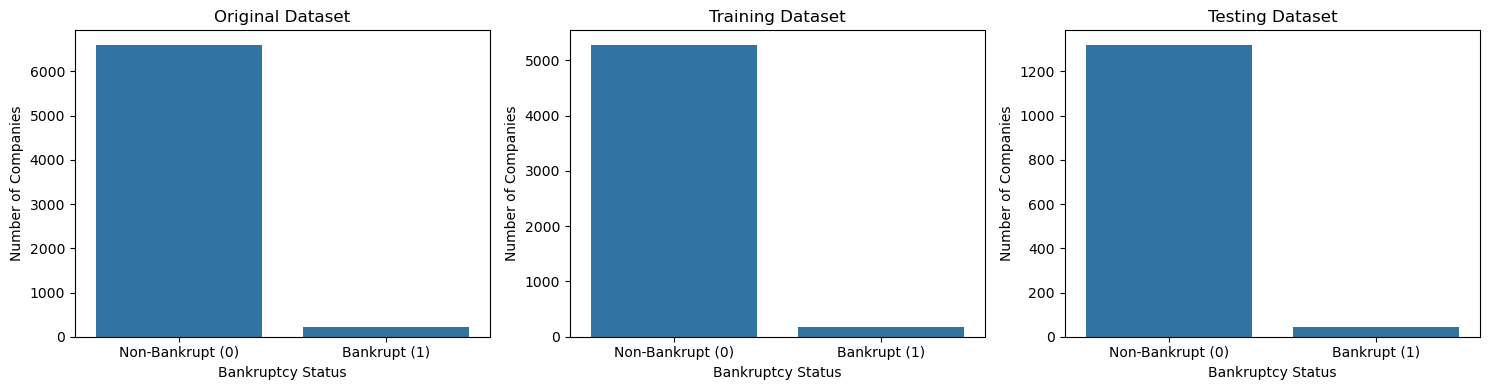

In [6]:
# Visualize class distribution

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

datasets = [
    ("Original Dataset", y),
    ("Training Dataset", y_train),
    ("Testing Dataset", y_test)
]

for ax, (title, target) in zip(axes, datasets):
    sns.countplot(x=target, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Bankruptcy Status")
    ax.set_ylabel("Number of Companies")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Non-Bankrupt (0)", "Bankrupt (1)"])

plt.tight_layout()
plt.show()

## 5. Class Imbalance Handling Strategy

The dataset contains a significantly smaller number of bankrupt companies compared to non-bankrupt companies.

This imbalance can cause machine learning models to become biased towards the majority class.

To address this issue, multiple approaches will be explored, including:

1. Class Weighting
2. Random Undersampling
3. SMOTE (Synthetic Minority Over-sampling Technique)

These techniques will be applied only to the training data. The original test dataset will remain unchanged to ensure a fair evaluation of model performance.

In [7]:
# Analyze class distribution in training data

train_class_counts = y_train.value_counts().sort_index()

train_class_percentages = (
    y_train.value_counts(normalize=True).sort_index() * 100
)

train_imbalance_summary = pd.DataFrame({
    "Class": ["Non-Bankrupt (0)", "Bankrupt (1)"],
    "Count": train_class_counts.values,
    "Percentage": train_class_percentages.values
})

display(train_imbalance_summary.round(2))

,Class,Count,Percentage
0,Non-Bankrupt (0),5279,96.77
1,Bankrupt (1),176,3.23


### 5.1 Class Imbalance Ratio

The class imbalance ratio is calculated by dividing the number of majority-class observations by the number of minority-class observations.

This ratio helps quantify the difference between the two classes and provides useful information for selecting appropriate imbalance-handling techniques.

In [8]:
# Calculate class imbalance ratio

majority_count = y_train.value_counts()[0]
minority_count = y_train.value_counts()[1]

imbalance_ratio = majority_count / minority_count

print("Majority Class Count:", majority_count)
print("Minority Class Count:", minority_count)
print("Class Imbalance Ratio:", round(imbalance_ratio, 2))

print(
    f"\nThere are approximately {imbalance_ratio:.2f} "
    "non-bankrupt companies for every bankrupt company."
)

Majority Class Count: 5279
Minority Class Count: 176
Class Imbalance Ratio: 29.99

There are approximately 29.99 non-bankrupt companies for every bankrupt company.


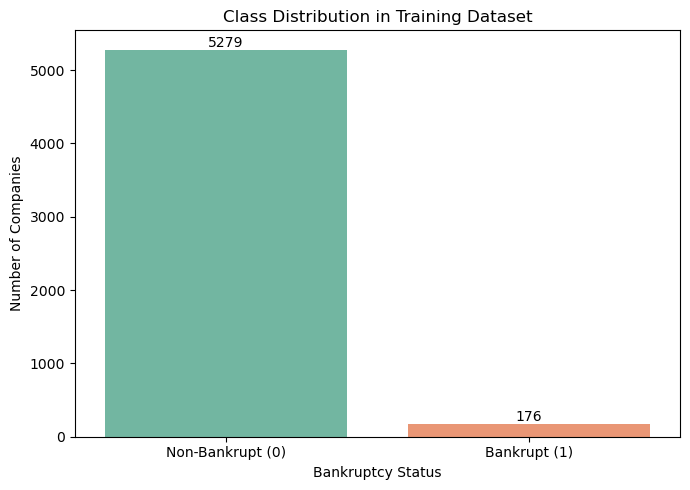

In [9]:
# Visualize training class distribution

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    x=y_train,
    hue=y_train,
    palette="Set2",
    legend=False
)

plt.title("Class Distribution in Training Dataset")
plt.xlabel("Bankruptcy Status")
plt.ylabel("Number of Companies")
plt.xticks([0, 1], ["Non-Bankrupt (0)", "Bankrupt (1)"])

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

### 5.2 Class Weighting

Class weighting assigns higher importance to the minority class during model training.

Since bankrupt companies are underrepresented, a higher penalty can be assigned to incorrect predictions of the bankrupt class.

The balanced class weight ratio is calculated using the training data only.

In [10]:
# Calculate balanced class weights

from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weight_dict = dict(zip(classes, class_weights))

print("Class Weights:", class_weight_dict)

Class Weights: {np.int64(0): np.float64(0.5166698238302709), np.int64(1): np.float64(15.497159090909092)}


## 6. Feature Scaling and Preprocessing

Financial indicators may have different numerical ranges and scales. Feature scaling is therefore necessary for distance-based algorithms and models that are sensitive to feature magnitude.

In this project, StandardScaler will be used to standardize numerical features.

To prevent data leakage, the scaler will be fitted only on the training data. The fitted scaler will then be used to transform both training and testing data.

Resampling techniques such as SMOTE will be applied only after scaling the training data.

In [11]:
# Import preprocessing tools

from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler
scaler = StandardScaler()

In [12]:
# Fit scaler on training data and transform

X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

# Convert arrays back to DataFrames
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

print("Scaled Training Data Shape:", X_train_scaled.shape)
print("Scaled Testing Data Shape:", X_test_scaled.shape)

Scaled Training Data Shape: (5455, 94)
Scaled Testing Data Shape: (1364, 94)


### 6.1 Verify Feature Scaling

The mean and standard deviation of selected scaled features are examined to verify the standardization process.

The training features should have approximately zero mean and unit standard deviation.

In [13]:
# Check mean and standard deviation of scaled training features

scaling_summary = pd.DataFrame({
    "Mean": X_train_scaled.mean(),
    "Standard Deviation": X_train_scaled.std()
})

display(scaling_summary.head(10).round(4))

,Mean,Standard Deviation
ROA(C) before interest and depreciation before interest,0.0,1.0001
ROA(A) before interest and % after tax,0.0,1.0001
ROA(B) before interest and depreciation after tax,0.0,1.0001
Operating Gross Margin,0.0,1.0001
Realized Sales Gross Margin,0.0,1.0001
Operating Profit Rate,-0.0,1.0001
Pre-tax net Interest Rate,0.0,1.0001
After-tax net Interest Rate,-0.0,1.0001
Non-industry income and expenditure/revenue,0.0,1.0001
Continuous interest rate (after tax),0.0,1.0001


In [14]:
# Check for invalid values after scaling

print("Infinite values in training data:",
      np.isinf(X_train_scaled).sum().sum())

print("Missing values in training data:",
      X_train_scaled.isnull().sum().sum())

print("Infinite values in test data:",
      np.isinf(X_test_scaled).sum().sum())

print("Missing values in test data:",
      X_test_scaled.isnull().sum().sum())

Infinite values in training data: 0
Missing values in training data: 0
Infinite values in test data: 0
Missing values in test data: 0


## 7. Build Preprocessing and Resampling Pipelines

To handle class imbalance and prevent data leakage, preprocessing and resampling operations will be integrated into machine learning pipelines.

Three approaches will be evaluated:

1. Class Weighting
2. Random Undersampling
3. SMOTE

Scaling and resampling will be performed within each training fold during cross-validation. This ensures that validation data remains untouched by the resampling process.

In [15]:
# Import required libraries

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [16]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


### 7.1 Define Classification Models

Three classification algorithms are selected for initial experimentation:

- Logistic Regression
- Random Forest
- Support Vector Machine (SVM)

These algorithms represent different classification approaches and will be evaluated using multiple imbalance-handling strategies.

In [17]:
from sklearn.base import clone

# Define models without class weighting

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "SVM": SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    )
}

### 7.2 Define Imbalance Handling Strategies

Three different approaches will be compared:

1. Class Weighting: Assigns greater importance to the minority class.
2. Random Undersampling: Reduces the number of majority-class observations.
3. SMOTE: Generates synthetic minority-class observations.

Resampling will be performed only within the training folds.

In [18]:
# Define imbalance handling strategies

sampling_strategies = {
    "Class Weighting": None,

    "Random Undersampling": RandomUnderSampler(
        random_state=42
    ),

    "SMOTE": SMOTE(
        random_state=42,
        k_neighbors=5
    )
}

print("Imbalance handling strategies defined:")
for strategy in sampling_strategies:
    print("-", strategy)

Imbalance handling strategies defined:
- Class Weighting
- Random Undersampling
- SMOTE


### 7.3 Create Machine Learning Pipelines

A separate pipeline will be created for each combination of classification algorithm and imbalance-handling strategy.

The pipeline follows this sequence:

1. StandardScaler
2. Resampling technique, when applicable
3. Classification algorithm

For class weighting, no resampling will be performed. For Random Undersampling and SMOTE, the sampling operation will be applied only to the training folds.

This approach helps prevent data leakage during cross-validation.

In [19]:
## Create separate pipelines for each imbalance strategy

pipelines = {}

for strategy_name, sampler in sampling_strategies.items():

    for model_name, base_model in models.items():

        # Create an independent copy of the model
        model = clone(base_model)

        # Apply class weighting only in the class weighting strategy
        if strategy_name == "Class Weighting":

            if model_name == "Random Forest":
                model.set_params(class_weight="balanced_subsample")
            else:
                model.set_params(class_weight="balanced")

        steps = [
            ("scaler", StandardScaler())
        ]

        # Apply resampling only for sampling strategies
        if sampler is not None:
            steps.append(("sampler", clone(sampler)))

        steps.append(("classifier", model))

        pipelines[f"{model_name} + {strategy_name}"] = Pipeline(steps)

print("Total pipelines created:", len(pipelines))

for name in pipelines:
    print(name)

Total pipelines created: 9
Logistic Regression + Class Weighting
Random Forest + Class Weighting
SVM + Class Weighting
Logistic Regression + Random Undersampling
Random Forest + Random Undersampling
SVM + Random Undersampling
Logistic Regression + SMOTE
Random Forest + SMOTE
SVM + SMOTE


## 8. Model Evaluation Using Cross-Validation

Stratified 5-Fold Cross-Validation is used to evaluate the classification pipelines.

Stratification preserves the class distribution in each fold, which is important for this highly imbalanced dataset.

The models will be evaluated using the following metrics:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Average Precision (PR-AUC)

Since bankruptcy prediction focuses on identifying financially distressed companies, recall, F1-score and Average Precision will receive particular attention.

In [20]:
# Define cross-validation strategy

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

print("Stratified 5-Fold Cross-Validation configured.")
print("Evaluation metrics:", list(scoring.keys()))

Stratified 5-Fold Cross-Validation configured.
Evaluation metrics: ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'pr_auc']


### 8.1 Evaluate Classification Pipelines

Each classification pipeline is evaluated using Stratified 5-Fold Cross-Validation.

All preprocessing, scaling and resampling operations are performed independently within each training fold.

The mean performance across the five folds is calculated to compare the different model and imbalance-handling combinations.

In [21]:
# Evaluate all pipelines using cross-validation

cv_results = []

for pipeline_name, pipeline in pipelines.items():

    print(f"Evaluating: {pipeline_name}")

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    result = {
        "Model": pipeline_name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "PR-AUC": scores["test_pr_auc"].mean()
    }

    cv_results.append(result)

print("\nCross-validation completed.")

Evaluating: Logistic Regression + Class Weighting
Evaluating: Random Forest + Class Weighting
Evaluating: SVM + Class Weighting
Evaluating: Logistic Regression + Random Undersampling
Evaluating: Random Forest + Random Undersampling
Evaluating: SVM + Random Undersampling
Evaluating: Logistic Regression + SMOTE
Evaluating: Random Forest + SMOTE
Evaluating: SVM + SMOTE

Cross-validation completed.


In [22]:
# Create model comparison table

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

display(cv_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Random Forest + Class Weighting,0.9679,0.5231,0.1140,0.1823,0.9258,0.3708
1,Random Forest + SMOTE,0.9560,0.3754,0.4946,0.4235,0.9328,0.3590
2,Random Forest + Random Undersampling,0.8504,0.1634,0.8633,0.2741,0.9277,0.3445
3,SVM + Random Undersampling,0.8288,0.1469,0.8862,0.2516,0.9225,0.3391
4,Logistic Regression + SMOTE,0.8772,0.1740,0.7386,0.2812,0.8874,0.3333
5,Logistic Regression + Class Weighting,0.8715,0.1706,0.7613,0.2782,0.8861,0.3271
6,SVM + Class Weighting,0.8984,0.1878,0.6367,0.2892,0.8987,0.2941
7,SVM + SMOTE,0.8935,0.1733,0.6025,0.2686,0.8991,0.2918
8,Logistic Regression + Random Undersampling,0.8407,0.1487,0.8238,0.2515,0.8817,0.2852


### 8.2 Model Performance Comparison

The classification models are compared using their cross-validation F1-score and Average Precision (PR-AUC).

These metrics provide useful insights into how effectively each model identifies the minority bankruptcy class.

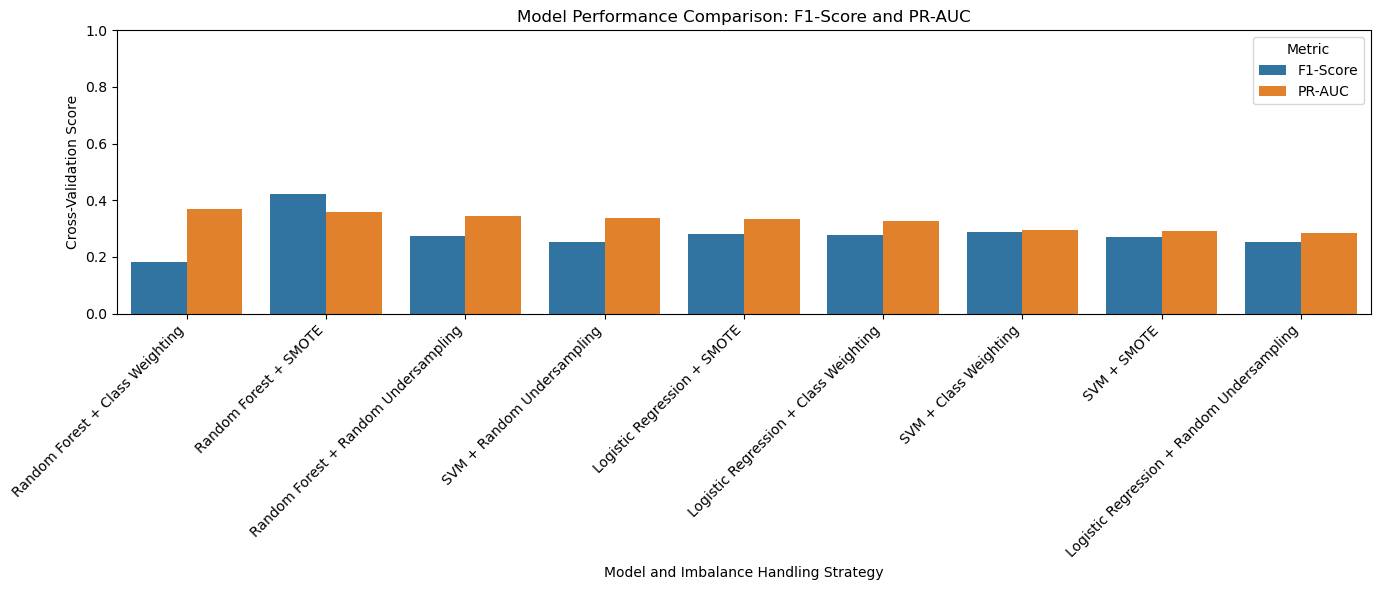

In [23]:
# Compare F1-score and PR-AUC

comparison_data = cv_results_df.melt(
    id_vars="Model",
    value_vars=["F1-Score", "PR-AUC"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(14, 6))

sns.barplot(
    data=comparison_data,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Model Performance Comparison: F1-Score and PR-AUC")
plt.xlabel("Model and Imbalance Handling Strategy")
plt.ylabel("Cross-Validation Score")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

### 8.3 Selection of Candidate Models

The models are ranked according to their Average Precision (PR-AUC) scores.

The top-performing models will be considered candidates for further evaluation.

However, the final model will not be selected using a single metric alone. Bankruptcy recall, precision, F1-score and ROC-AUC will also be considered.

In [24]:
# Display top 3 candidate models

top_3_models = cv_results_df.head(3)

display(top_3_models.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Random Forest + Class Weighting,0.9679,0.5231,0.1140,0.1823,0.9258,0.3708
1,Random Forest + SMOTE,0.9560,0.3754,0.4946,0.4235,0.9328,0.3590
2,Random Forest + Random Undersampling,0.8504,0.1634,0.8633,0.2741,0.9277,0.3445


### 8.4 Cross-Validation Findings

The cross-validation results show that different imbalance-handling techniques produce different classification outcomes.

Random Forest with SMOTE achieved the highest F1-score of 0.4235, with a recall of 0.4946 and precision of 0.3754.

Random Forest with Random Undersampling achieved the highest recall of 0.8633, but its precision was relatively low at 0.1634.

Random Forest with Class Weighting achieved the highest precision of 0.5231, but its recall was only 0.1140.

Based on the balance between precision and recall, Random Forest with SMOTE is selected as the primary candidate for further evaluation.

The final model selection will also consider performance on the untouched test dataset.

In [25]:
# Display all 9 model results

display(
    cv_results_df.sort_values(
        by="PR-AUC",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Random Forest + Class Weighting,0.9679,0.5231,0.1140,0.1823,0.9258,0.3708
1,Random Forest + SMOTE,0.9560,0.3754,0.4946,0.4235,0.9328,0.3590
2,Random Forest + Random Undersampling,0.8504,0.1634,0.8633,0.2741,0.9277,0.3445
3,SVM + Random Undersampling,0.8288,0.1469,0.8862,0.2516,0.9225,0.3391
4,Logistic Regression + SMOTE,0.8772,0.1740,0.7386,0.2812,0.8874,0.3333
5,Logistic Regression + Class Weighting,0.8715,0.1706,0.7613,0.2782,0.8861,0.3271
6,SVM + Class Weighting,0.8984,0.1878,0.6367,0.2892,0.8987,0.2941
7,SVM + SMOTE,0.8935,0.1733,0.6025,0.2686,0.8991,0.2918
8,Logistic Regression + Random Undersampling,0.8407,0.1487,0.8238,0.2515,0.8817,0.2852


## 9. Candidate Model Selection

The cross-validation results are analyzed to identify the strongest candidate from each classification algorithm.

The selection considers F1-score, Recall, Precision and Average Precision (PR-AUC).

The objective is to identify complementary models that may improve bankruptcy prediction when combined through an ensemble learning approach.

In [26]:
# Identify the best imbalance strategy for each algorithm

cv_results_df["Algorithm"] = cv_results_df["Model"].str.split(" + ").str[0]

best_per_algorithm = (
    cv_results_df
    .sort_values(
        by=["F1-Score", "PR-AUC"],
        ascending=False
    )
    .groupby("Algorithm", as_index=False)
    .first()
    .sort_values(by="F1-Score", ascending=False)
    .reset_index(drop=True)
)

display(
    best_per_algorithm[
        ["Model", "Accuracy", "Precision", "Recall",
         "F1-Score", "ROC-AUC", "PR-AUC"]
    ].round(4)
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Random Forest + SMOTE,0.9560,0.3754,0.4946,0.4235,0.9328,0.3590
1,SVM + Class Weighting,0.8984,0.1878,0.6367,0.2892,0.8987,0.2941
2,Logistic Regression + SMOTE,0.8772,0.1740,0.7386,0.2812,0.8874,0.3333
3,Logistic Regression + Class Weighting,0.8715,0.1706,0.7613,0.2782,0.8861,0.3271
4,Random Forest + Random Undersampling,0.8504,0.1634,0.8633,0.2741,0.9277,0.3445
5,SVM + SMOTE,0.8935,0.1733,0.6025,0.2686,0.8991,0.2918
6,SVM + Random Undersampling,0.8288,0.1469,0.8862,0.2516,0.9225,0.3391
7,Logistic Regression + Random Undersampling,0.8407,0.1487,0.8238,0.2515,0.8817,0.2852
8,Random Forest + Class Weighting,0.9679,0.5231,0.1140,0.1823,0.9258,0.3708


### 9.1 Selection of Candidate Models

The best-performing pipeline from each algorithm is considered for ensemble development.

Random Forest with SMOTE is retained as an important candidate based on its cross-validation F1-score.

Other algorithms will be considered based on their performance and complementary classification behaviour.

The final candidate selection will be evaluated before constructing the Voting Classifier.

In [27]:
# Select the best pipeline from each algorithm

candidate_model_names = best_per_algorithm["Model"].tolist()

candidate_pipelines = {
    name: pipelines[name]
    for name in candidate_model_names
}

print("Selected candidate models:")

for name in candidate_pipelines:
    print("-", name)

print("\nTotal candidate models:", len(candidate_pipelines))

Selected candidate models:
- Random Forest + SMOTE
- SVM + Class Weighting
- Logistic Regression + SMOTE
- Logistic Regression + Class Weighting
- Random Forest + Random Undersampling
- SVM + SMOTE
- SVM + Random Undersampling
- Logistic Regression + Random Undersampling
- Random Forest + Class Weighting

Total candidate models: 9


# Compare candidate F1-score and PR-AUC

candidate_plot_data = best_per_algorithm.melt(
    id_vars="Algorithm",
    value_vars=["F1-Score", "PR-AUC"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=candidate_plot_data,
    x="Algorithm",
    y="Score",
    hue="Metric"
)

plt.title("Best Candidate Model from Each Algorithm")
plt.xlabel("Classification Algorithm")
plt.ylabel("Cross-Validation Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## 10. Voting Classifier – Ensemble Learning

Ensemble learning combines multiple machine learning models to improve predictive performance.

In this section, a Soft Voting Classifier is developed using the selected candidate models.

Soft Voting combines the predicted class probabilities from individual models to generate the final prediction.

The selected pipelines retain their respective preprocessing and class imbalance handling strategies.

The ensemble will be evaluated using Stratified 5-Fold Cross-Validation.

In [28]:
# Import VotingClassifier

from sklearn.ensemble import VotingClassifier

print("Voting Classifier imported successfully.")

Voting Classifier imported successfully.


In [29]:
# Prepare candidate estimators for voting

estimators = [
    (name, clone(pipeline))
    for name, pipeline in candidate_pipelines.items()
]

print("Candidate estimators:")

for name, estimator in estimators:
    print("-", name)

print("\nTotal candidate estimators:", len(estimators))

Candidate estimators:
- Random Forest + SMOTE
- SVM + Class Weighting
- Logistic Regression + SMOTE
- Logistic Regression + Class Weighting
- Random Forest + Random Undersampling
- SVM + SMOTE
- SVM + Random Undersampling
- Logistic Regression + Random Undersampling
- Random Forest + Class Weighting

Total candidate estimators: 9


### 10.1 Build Soft Voting Classifier

A Soft Voting Classifier is created by combining the selected candidate pipelines.

Each model contributes its predicted class probabilities. The probabilities are averaged to determine the final predicted class.

This approach allows the ensemble to consider the probability estimates from multiple classification algorithms.

In [30]:
# Create Soft Voting Classifier

voting_model = VotingClassifier(
    estimators=estimators,
    voting="soft",
    n_jobs=-1
)

print("Soft Voting Classifier created successfully.")

Soft Voting Classifier created successfully.


### 10.2 Evaluate Voting Classifier

The Voting Classifier is evaluated using Stratified 5-Fold Cross-Validation.

Its performance is compared with the individual candidate models using Accuracy, Precision, Recall, F1-score, ROC-AUC and Average Precision.

In [31]:
# Evaluate Voting Classifier

voting_scores = cross_validate(
    voting_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    error_score="raise"
)

voting_results = {
    "Model": "Soft Voting Classifier",
    "Accuracy": voting_scores["test_accuracy"].mean(),
    "Precision": voting_scores["test_precision"].mean(),
    "Recall": voting_scores["test_recall"].mean(),
    "F1-Score": voting_scores["test_f1"].mean(),
    "ROC-AUC": voting_scores["test_roc_auc"].mean(),
    "PR-AUC": voting_scores["test_pr_auc"].mean()
}

voting_results_df = pd.DataFrame([voting_results])

display(voting_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Soft Voting Classifier,0.9248,0.2529,0.6705,0.3663,0.9274,0.3704


In [32]:
# Compare individual candidates with Voting Classifier

individual_results = best_per_algorithm[
    ["Model", "Accuracy", "Precision", "Recall",
     "F1-Score", "ROC-AUC", "PR-AUC"]
].copy()

final_cv_comparison = pd.concat(
    [individual_results, voting_results_df],
    ignore_index=True
)

display(
    final_cv_comparison.sort_values(
        by="F1-Score",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Random Forest + SMOTE,0.9560,0.3754,0.4946,0.4235,0.9328,0.3590
9,Soft Voting Classifier,0.9248,0.2529,0.6705,0.3663,0.9274,0.3704
1,SVM + Class Weighting,0.8984,0.1878,0.6367,0.2892,0.8987,0.2941
2,Logistic Regression + SMOTE,0.8772,0.1740,0.7386,0.2812,0.8874,0.3333
3,Logistic Regression + Class Weighting,0.8715,0.1706,0.7613,0.2782,0.8861,0.3271
4,Random Forest + Random Undersampling,0.8504,0.1634,0.8633,0.2741,0.9277,0.3445
5,SVM + SMOTE,0.8935,0.1733,0.6025,0.2686,0.8991,0.2918
6,SVM + Random Undersampling,0.8288,0.1469,0.8862,0.2516,0.9225,0.3391
7,Logistic Regression + Random Undersampling,0.8407,0.1487,0.8238,0.2515,0.8817,0.2852
8,Random Forest + Class Weighting,0.9679,0.5231,0.1140,0.1823,0.9258,0.3708


In [33]:
display(
    final_cv_comparison
    .sort_values(by="PR-AUC", ascending=False)
    .round(4)
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
8,Random Forest + Class Weighting,0.9679,0.5231,0.1140,0.1823,0.9258,0.3708
9,Soft Voting Classifier,0.9248,0.2529,0.6705,0.3663,0.9274,0.3704
0,Random Forest + SMOTE,0.9560,0.3754,0.4946,0.4235,0.9328,0.3590
4,Random Forest + Random Undersampling,0.8504,0.1634,0.8633,0.2741,0.9277,0.3445
6,SVM + Random Undersampling,0.8288,0.1469,0.8862,0.2516,0.9225,0.3391
2,Logistic Regression + SMOTE,0.8772,0.1740,0.7386,0.2812,0.8874,0.3333
3,Logistic Regression + Class Weighting,0.8715,0.1706,0.7613,0.2782,0.8861,0.3271
1,SVM + Class Weighting,0.8984,0.1878,0.6367,0.2892,0.8987,0.2941
5,SVM + SMOTE,0.8935,0.1733,0.6025,0.2686,0.8991,0.2918
7,Logistic Regression + Random Undersampling,0.8407,0.1487,0.8238,0.2515,0.8817,0.2852


## 11. Hyperparameter Tuning – Random Forest with SMOTE

Hyperparameter tuning is performed using RandomizedSearchCV to identify the optimal parameters for the Random Forest model.

The tuning process uses Stratified 5-Fold Cross-Validation and F1-Score as the optimization metric.

The SMOTE sampling technique is kept inside the pipeline to prevent data leakage.

In [34]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone

# Select Random Forest + SMOTE pipeline
rf_smote_pipeline = clone(pipelines["Random Forest + SMOTE"])

# Define hyperparameter search space
param_distributions = {
    "classifier__n_estimators": [100, 200, 300, 400],
    "classifier__max_depth": [None, 5, 10, 15, 20],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2"],
    "sampler__k_neighbors": [3, 5, 7]
}

# Randomized Search
random_search = RandomizedSearchCV(
    estimator=rf_smote_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit using training data only
random_search.fit(X_train, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(round(random_search.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters:
{'sampler__k_neighbors': 3, 'classifier__n_estimators': 200, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'log2', 'classifier__max_depth': 20}

Best Cross-Validation F1-Score:
0.4224


## 12. Final Model Evaluation

The best-performing Random Forest model with SMOTE is evaluated on the unseen test dataset.

The model is evaluated using Accuracy, Precision, Recall, F1-Score, ROC-AUC, Average Precision, and Confusion Matrix.

The test dataset is kept separate from the training and hyperparameter tuning process to obtain an unbiased performance estimate.

In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Get the best tuned model
best_model = random_search.best_estimator_

# Predict on unseen test data
y_test_pred = best_model.predict(X_test)
y_test_prob = best_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("Final Test Performance")
print("----------------------")
print("Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print("Precision:", round(precision_score(y_test, y_test_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_test_pred, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_test, y_test_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_test_prob), 4))
print("Average Precision:", round(average_precision_score(y_test, y_test_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, zero_division=0))

Final Test Performance
----------------------
Accuracy: 0.956
Precision: 0.3919
Recall: 0.6591
F1-Score: 0.4915
ROC-AUC: 0.9444
Average Precision: 0.5023

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1320
           1       0.39      0.66      0.49        44

    accuracy                           0.96      1364
   macro avg       0.69      0.81      0.73      1364
weighted avg       0.97      0.96      0.96      1364



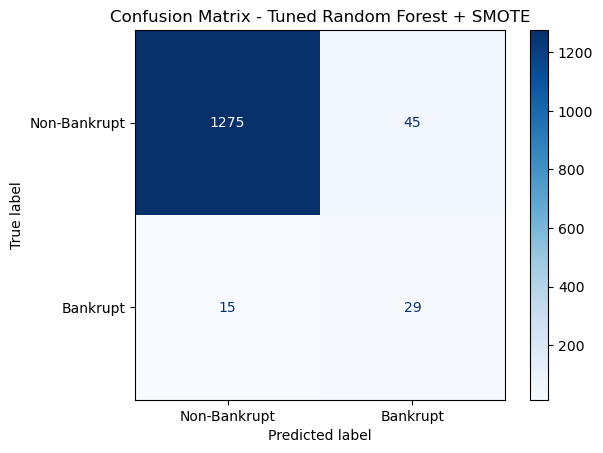

In [36]:
cm = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Bankrupt", "Bankrupt"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Tuned Random Forest + SMOTE")
plt.show()

## 13. ROC Curve and Precision-Recall Curve

ROC Curve illustrates the trade-off between True Positive Rate and False Positive Rate at different classification thresholds.

Precision-Recall Curve shows the relationship between Precision and Recall at different thresholds.

For an imbalanced bankruptcy dataset, the Precision-Recall Curve is particularly important for evaluating the model's ability to identify bankrupt companies.

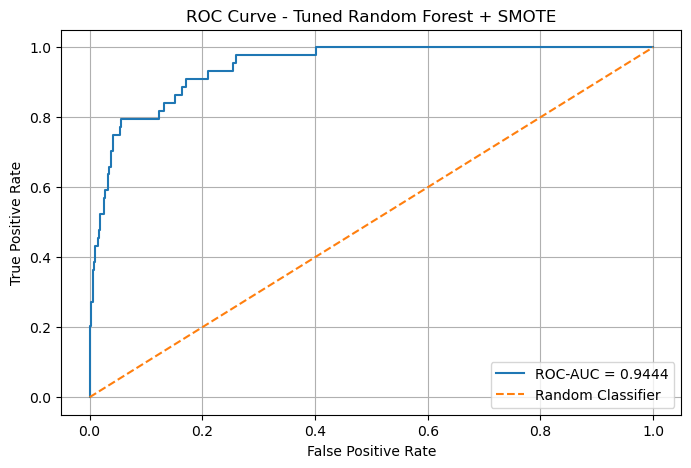

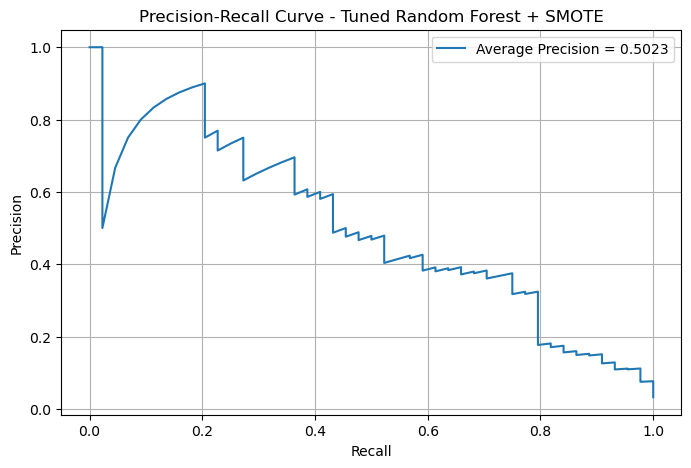

In [37]:
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc,
    average_precision_score
)

# Calculate ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_test_prob)
roc_auc = auc(fpr, tpr)

# Calculate Precision-Recall curve
precision, recall, pr_thresholds = precision_recall_curve(
    y_test, y_test_prob
)
avg_precision = average_precision_score(y_test, y_test_prob)

# Plot ROC Curve
plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned Random Forest + SMOTE")
plt.legend()
plt.grid()
plt.show()

# Plot Precision-Recall Curve
plt.figure(figsize=(8, 5))
plt.plot(recall, precision, label=f"Average Precision = {avg_precision:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Tuned Random Forest + SMOTE")
plt.legend()
plt.grid()
plt.show()

## 14. Feature Importance Analysis

Feature importance analysis identifies the financial indicators that contribute most to the Random Forest model's predictions.

The feature importance scores are extracted from the tuned Random Forest classifier.

The top 15 most important features are visualized to understand the key factors associated with bankruptcy prediction.

In [38]:
# Extract the Random Forest classifier from the fitted pipeline
rf_model = best_model.named_steps["classifier"]

# Create feature importance DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
feature_importance_df = (
    feature_importance_df
    .sort_values(by="Importance", ascending=False)
    .reset_index(drop=True)
)

# Display top 15 features
top_15_features = feature_importance_df.head(15)

display(top_15_features.round(4))

,Feature,Importance
0,Continuous interest rate (after tax),0.0675
1,Borrowing dependency,0.0550
2,Total income/Total expense,0.0392
3,Net Income to Total Assets,0.0337
4,Retained Earnings to Total Assets,0.0324
5,Equity to Liability,0.0323
6,Persistent EPS in the Last Four Seasons,0.0323
7,Non-industry income and expenditure/revenue,0.0310
8,ROA(B) before interest and depreciation after tax,0.0295
9,Debt ratio %,0.0279


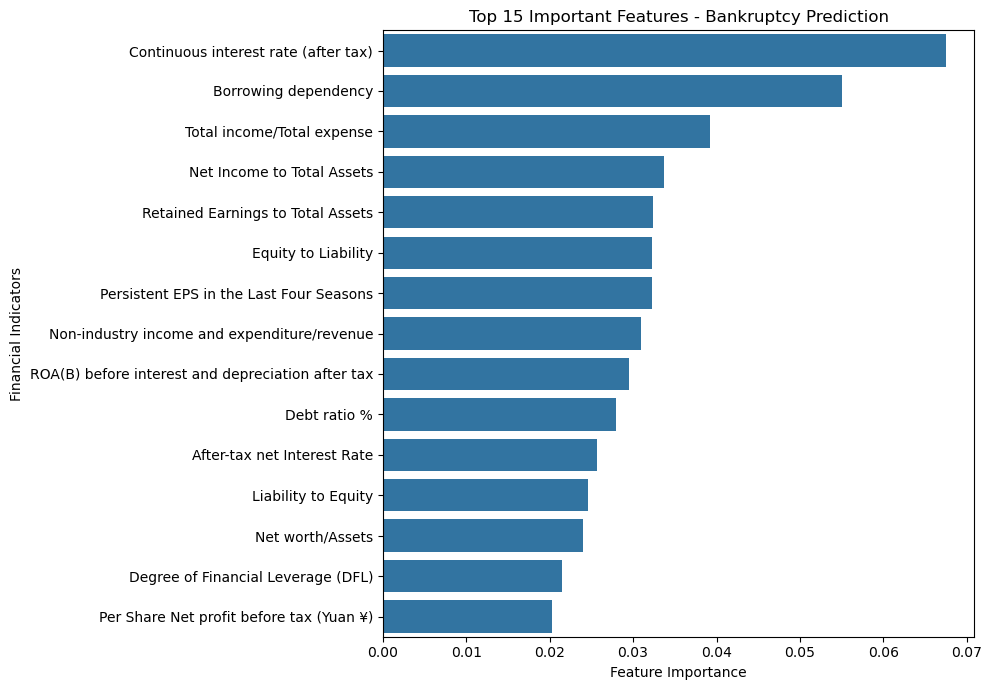

In [39]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_15_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features - Bankruptcy Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Financial Indicators")
plt.tight_layout()
plt.show()

## 15. Classification Threshold Optimization

The default classification threshold of 0.5 may not provide the best balance between Precision and Recall for an imbalanced dataset.

In this section, out-of-fold probability predictions are generated using Stratified 5-Fold Cross-Validation on the training dataset.

Different classification thresholds are evaluated using the F1-Score. The selected threshold is then evaluated on the untouched test dataset.

In [40]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

# Generate out-of-fold probability predictions
oof_prob = cross_val_predict(
    best_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Out-of-fold predictions generated successfully.")
print("Total predictions:", len(oof_prob))

Out-of-fold predictions generated successfully.
Total predictions: 5455


In [41]:
threshold_results = []

thresholds = np.arange(0.10, 0.91, 0.05)

for threshold in thresholds:
    oof_pred = (oof_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, oof_pred, zero_division=0),
        "Recall": recall_score(y_train, oof_pred, zero_division=0),
        "F1-Score": f1_score(y_train, oof_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

best_threshold = threshold_df.loc[
    threshold_df["F1-Score"].idxmax(), "Threshold"
]

print("Selected Threshold:", round(best_threshold, 2))

,Threshold,Precision,Recall,F1-Score
0,0.10,0.1224,0.9205,0.2161
1,0.15,0.1484,0.8920,0.2545
2,0.20,0.1786,0.8636,0.2960
3,0.25,0.2019,0.8239,0.3244
4,0.30,0.2317,0.7898,0.3582
5,0.35,0.2577,0.7159,0.3789
6,0.40,0.2759,0.6648,0.3900
7,0.45,0.3006,0.5909,0.3985
8,0.50,0.3379,0.5568,0.4206
9,0.55,0.3697,0.5000,0.4251


Selected Threshold: 0.6


In [42]:
# Apply the selected threshold to test probabilities
y_test_tuned_threshold = (y_test_prob >= best_threshold).astype(int)

print("Test Performance with Optimized Threshold")
print("------------------------------------------")

print("Precision:", round(
    precision_score(y_test, y_test_tuned_threshold, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_test, y_test_tuned_threshold, zero_division=0), 4
))

print("F1-Score:", round(
    f1_score(y_test, y_test_tuned_threshold, zero_division=0), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_tuned_threshold))

Test Performance with Optimized Threshold
------------------------------------------
Precision: 0.451
Recall: 0.5227
F1-Score: 0.4842

Confusion Matrix:
[[1292   28]
 [  21   23]]


## 16. Final Model Performance Comparison

In this section, the model's performance using the default classification threshold (0.50) is compared with its performance using the optimized threshold.

The comparison focuses on Precision, Recall, and F1-Score to understand the impact of threshold optimization on bankruptcy prediction.

In [43]:
comparison_data = {
    "Metric": ["Precision", "Recall", "F1-Score"],
    "Default Threshold (0.50)": [
        precision_score(y_test, y_test_pred, zero_division=0),
        recall_score(y_test, y_test_pred, zero_division=0),
        f1_score(y_test, y_test_pred, zero_division=0)
    ],
    "Optimized Threshold": [
        precision_score(y_test, y_test_tuned_threshold, zero_division=0),
        recall_score(y_test, y_test_tuned_threshold, zero_division=0),
        f1_score(y_test, y_test_tuned_threshold, zero_division=0)
    ]
}

threshold_comparison_df = pd.DataFrame(comparison_data)

display(threshold_comparison_df.round(4))

,Metric,Default Threshold (0.50),Optimized Threshold
0,Precision,0.3919,0.4510
1,Recall,0.6591,0.5227
2,F1-Score,0.4915,0.4842


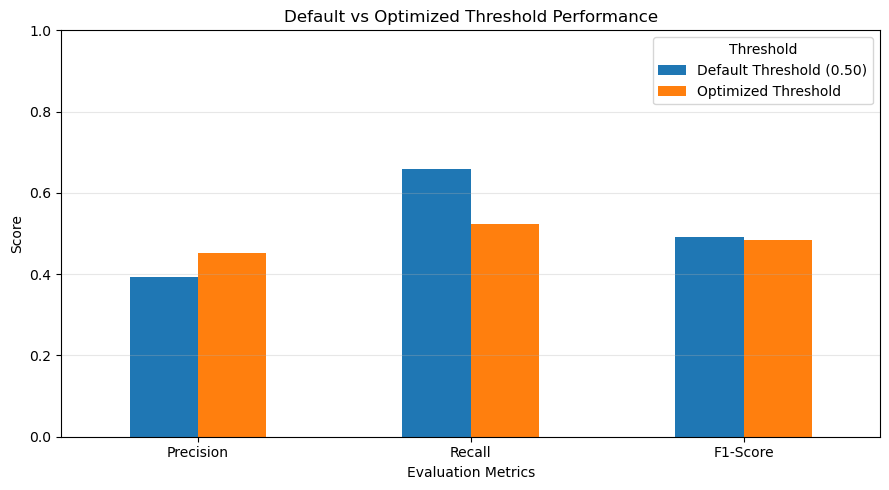

In [44]:
threshold_comparison_df.set_index("Metric").plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Default vs Optimized Threshold Performance")
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(title="Threshold")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 17. Final Conclusion

The project developed a machine learning classification model to predict corporate bankruptcy using financial indicators.

Multiple classification algorithms and class imbalance handling techniques were evaluated using Stratified Cross-Validation.

Random Forest with SMOTE achieved the highest F1-Score among the individual candidate models, while the Soft Voting Classifier demonstrated higher Recall.

Hyperparameter tuning was performed on the Random Forest with SMOTE pipeline.

The final model was evaluated on an unseen test dataset using multiple classification metrics.

Threshold comparison showed that the default threshold of 0.50 provided a slightly better F1-Score and higher Recall than the optimized threshold.

The developed model can support financial risk assessment and decision-making. However, it should be used as a decision-support tool rather than a guarantee of future bankruptcy.

#### Limitations

- The test set contains only 44 bankrupt companies, so the performance estimates are uncertain; the test F1-score (0.49) is higher than the cross-validation F1-score (0.42) partly for this reason.
- Precision is moderate (about 0.39): roughly six out of ten bankruptcy alerts are false alarms.
- The data comes from a single market and period (Taiwan, 1999-2009), so the model may not generalize to other regions or economic conditions.
- Highly correlated and duplicate features were not removed before modeling, which affects how importance is shared between features.

#### Recommendations

The model should be used as a **decision-support tool for financial risk screening**, not as a guarantee of future bankruptcy. Possible improvements include removing redundant features, trying gradient boosting models (such as XGBoost or LightGBM), using a robust scaler or transformations for heavily skewed features, and validating the model on newer or external data.